# CMSC · AI ACOUSTIC · DATASET NOTEBOOK V1

**Misión:** `CMSC_AI_ACOUSTIC_DATASET_NOTEBOOK_V1_IMPLEMENTATION` · **Estado:** IMPLEMENTADO · **Ejecutado:** 2026-10-09T01:36:32Z
**Base:** C0 (`CAPTADO_INICIAL`) + C1 (ESC-50 `INVENTARIADO`, 428 clips) + `rules-v0`

---

## Qué es y qué NO es

Notebook **oficial** del estado del dato acústico del ecosistema. Construye, con lectura pura, una
radiografía reproducible del corpus acústico (propio y de referencia), y evalúa el clasificador
determinista `rules-v0` como **baseline honesto**.

**Invariantes respetados por diseño:**

| Invariante | Cumplimiento |
|---|---|
| Sin entrenar modelos | Sí — ninguna celda ajusta parámetros aprendidos |
| Sin tocar S81 | Sí — solo lectura; S81 sigue en `DISENO` |
| Sin tocar S82 | Sí — no se menciona ni activa |
| Sin modificar datasets | Sí — el notebook **solo lee**; no escribe en `data/` |
| Notebook únicamente | Sí — no crea rutas, componentes ni servicios |

> **Honestidad de estado (invariante de dominio).** `rules-v0` es una **heurística determinista**, no IA.
> Se presenta con `method:'rules-v0'` y estado visible **`SIM`**, **nunca** `REAL-LOCAL`. `confidence`
> es un *score de regla* en [0,1], **no** una probabilidad calibrada.

## Base de datos

| Capa | Ruta | Estado | Contenido |
|---|---|---|---|
| **C0** (propio) | `data/datasets/sigct_rural_acoustic/v1` | `CAPTADO_INICIAL` | 1 clip real (`silencio`), metadata 42 col, features v2 |
| **C1** (referencia) | `data/datasets/sigct_rural_acoustic/reference/esc50` | `INVENTARIADO` | 428 clips ESC-50 normalizados, 6 clases v1 |
| **rules-v0** | `tools/cmsc-data-logger/src/rules-v0.js` | `SIM` | clasificador determinista por umbrales |

> **Canon de capas (explícito).** **C0 = `REAL-LOCAL`** (audio rural propio) · **C1 = `REF`** (referencia
> externa) · **C2 = `Ontología`** (ontología / YAMNet, sin audio). Este notebook lee C0 y C1; C2 no aporta audio.

## Índice

1. Introducción · 2. Dataset C0 · 3. Dataset C1 · 4. EDA · 5. ETL · 6. Estadísticas ·
7. Visualizaciones · 8. Comparación C0 vs C1 · 9. Evaluación rules-v0 · 10. Roadmap ML

## Cómo ejecutar

Desde la raíz del repositorio: `python -m nbconvert --to notebook --execute --inplace notebooks/CMSC_AI_ACOUSTIC_DATASET_NOTEBOOK_V1.ipynb`.
El notebook localiza la raíz del repo por sí mismo; si el dataset no está materializado, se detiene con un
mensaje explícito (**no fabrica datos**).

In [1]:
# --- Configuracion: solo lectura, determinista, SIN entrenamiento ---
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)


def find_repo_root():
    """Localiza la raiz del repo por marcadores (no depende del cwd)."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "tools" / "cmsc-data-logger").exists() and (base / "data" / "datasets" / "sigct_rural_acoustic").exists():
            return base
    return here


REPO_ROOT = find_repo_root()
DS_ROOT = REPO_ROOT / "data" / "datasets" / "sigct_rural_acoustic"
C0_ROOT = DS_ROOT / "v1"
C1_ROOT = DS_ROOT / "reference" / "esc50"

# acoustic.feat.v2 -> 22 features, orden INMUTABLE (tools/cmsc-data-logger/src/constants.js)
FEATURE_SCHEMA_V2 = [
    "dominantHzNorm", "peakDbNorm", "centroidNorm", "flatness", "rms", "logEnergy", "levelDb",
    "bandPctLow", "bandPctMid", "bandPctHigh",
    "bandPeakLowNorm", "bandPeakMidNorm", "bandPeakHighNorm",
    "bandPeakDbLow", "bandPeakDbMid", "bandPeakDbHigh",
    "spectralBandwidthNorm", "spectralRolloffNorm", "zeroCrossingRate",
    "crestFactor", "spectralFlux", "profileEntropy",
]
assert len(FEATURE_SCHEMA_V2) == 22, "acoustic.feat.v2 debe tener 22 features"
WINDOW_SCHEMA_V2 = [f"mean_{f}" for f in FEATURE_SCHEMA_V2] + [f"std_{f}" for f in FEATURE_SCHEMA_V2]
assert len(WINDOW_SCHEMA_V2) == 44, "acoustic.feat.window.v2 debe tener 44 dims"

LIVE_CLASSES = ["silencio", "viento", "lluvia", "agua", "insectos", "ave", "voz", "motor"]
OOD_CLASS = "ruido_desconocido"
ALL_CLASSES = LIVE_CLASSES + [OOD_CLASS]

print("REPO_ROOT :", REPO_ROOT)
print("C0_ROOT   :", C0_ROOT, "| existe:", C0_ROOT.exists())
print("C1_ROOT   :", C1_ROOT, "| existe:", C1_ROOT.exists())
print("feat.v2   :", len(FEATURE_SCHEMA_V2), "features | window.v2:", len(WINDOW_SCHEMA_V2), "dims")
print("clases    :", ALL_CLASSES)

if not C0_ROOT.exists() or not C1_ROOT.exists():
    raise SystemExit(
        "Dataset no materializado: faltan C0 y/o C1. Este notebook NO fabrica datos "
        "(regla de honestidad). Ver docs/AI_ACOUSTIC_DATASET_GOVERNANCE_V1.md."
    )

REPO_ROOT : C:\Users\BagmDev\DevBadolgm\Proyectos\GitHub\sigcTiArural
C0_ROOT   : C:\Users\BagmDev\DevBadolgm\Proyectos\GitHub\sigcTiArural\data\datasets\sigct_rural_acoustic\v1 | existe: True
C1_ROOT   : C:\Users\BagmDev\DevBadolgm\Proyectos\GitHub\sigcTiArural\data\datasets\sigct_rural_acoustic\reference\esc50 | existe: True
feat.v2   : 22 features | window.v2: 44 dims
clases    : ['silencio', 'viento', 'lluvia', 'agua', 'insectos', 'ave', 'voz', 'motor', 'ruido_desconocido']


## 2. Dataset C0 (propio · `CAPTADO_INICIAL`)

C0 es el **corpus propio** del ecosistema (`sigct_rural_acoustic/v1`). `metadata/metadata.csv` es la
**única fuente de verdad** (contrato `schema.json` **1.3.0**, 42 columnas). Aquí reside el primer clip
real capturado con `cmsc_logger` (S30 → Logger). Estado: `CAPTADO_INICIAL`.

In [2]:
c0_meta = pd.read_csv(C0_ROOT / "metadata" / "metadata.csv")
c0_labels = pd.read_csv(C0_ROOT / "metadata" / "labels.csv")
c0_feats = pd.read_csv(C0_ROOT / "features" / "acoustic_features_v2.csv")
c0_env = json.loads((C0_ROOT / "features" / "acoustic_envelopes_v1.json").read_text(encoding="utf-8"))

print("metadata.csv :", c0_meta.shape, "-> columnas (schema 1.3.0)")
print("labels.csv   :", c0_labels.shape, "(9 clases: 8 vivas + 1 OOD)")
print("features     :", c0_feats.shape, "(1 fila = 1 clip; 4 contexto + 44 dims)")
print("envelopes    :", c0_env["count"], "clip(s) x", len(next(iter(c0_env["envelopes"].values()))), "frames rms")
print()
cols = ["sample_id", "file", "partition", "class_id", "duration_s", "sample_rate", "channels",
        "bit_depth", "source", "capture_source_rate", "resample_method",
        "feature_schema", "window_schema", "frames_count", "qc_status"]
print(c0_meta[cols].T.to_string())
print()
print("Esquema de features:", c0_feats["feature_schema"].unique().tolist(),
      "| ventana:", c0_feats["window_schema"].unique().tolist(),
      "| frame_count:", c0_feats["frame_count"].unique().tolist())

metadata.csv : (1, 42) -> columnas (schema 1.3.0)
labels.csv   : (9, 10) (9 clases: 8 vivas + 1 OOD)
features     : (1, 48) (1 fila = 1 clip; 4 contexto + 44 dims)
envelopes    : 1 clip(s) x 63 frames rms

                                                                                                                            0
sample_id                                                                                              ac_20261006_215109_000
file                 raw/silencio/ac_20261006_215109_000_f6fe2a1e010e17f068cc01fcba052d66cb3d446be5e2f4e36236f8dbc5784ae7.wav
partition                                                                                                          unassigned
class_id                                                                                                             silencio
duration_s                                                                                                                3.0
sample_rate                           

## 3. Dataset C1 (referencia · ESC-50 `INVENTARIADO`, 428 clips)

C1 es la **capa de referencia (`REF`)** (`reference/esc50/`), resultado del piloto H3. **No es audio rural propio**:
es material externo normalizado al contrato de clip (mono · 44.100 Hz · PCM16 · 3,0 s · ventana central)
y mapeado a las clases de `labels.csv` v1 mediante el mapeo canónico H2 §6. `partition=reference`: **jamás**
entra en `train/validation/test` de C0 ni en la evaluación de S81.

In [3]:
c1_ref = pd.read_csv(C1_ROOT / "metadata" / "ref_esc50.csv")
c1_map = pd.read_csv(C1_ROOT / "metadata" / "mapping_esc50_to_v1.csv")
c1_feats = pd.read_csv(C1_ROOT / "features" / "acoustic_features_ref_window_v2.csv")

print("ref_esc50.csv :", c1_ref.shape)
print("mapping       :", c1_map.shape, "filas")
print("features      :", c1_feats.shape)
print()
print("Mapeo canonico ESC-50 -> taxonomia v1:")
print(c1_map.to_string(index=False))
print()
print("Conteo por clase v1 (C1):")
cc = c1_ref["class_mapped_v1"].value_counts()
print(cc.reindex([c for c in LIVE_CLASSES if c in set(cc.index)]).to_string())
print()
print("Licencia por clip:", c1_ref["license"].value_counts().to_dict())
print("license_nc=True  :", int((c1_ref["license_nc"] == True).sum()), "de", len(c1_ref))
print("partition        :", c1_ref["partition"].unique().tolist())
print("source_id        :", c1_ref["source_id"].unique().tolist())
print("reference_status :", c1_ref["reference_status_clip"].value_counts().to_dict())

ref_esc50.csv : (428, 23)
mapping       : (11, 2) filas
features      : (428, 48)

Mapeo canonico ESC-50 -> taxonomia v1:
category_esc50 class_mapped_v1
          wind          viento
          rain          lluvia
   water_drops            agua
     sea_waves            agua
 pouring_water            agua
      crickets        insectos
       insects        insectos
chirping_birds             ave
       rooster             ave
          crow             ave
        engine           motor

Conteo por clase v1 (C1):
class_mapped_v1
viento       38
lluvia       40
agua        115
insectos     79
ave         119
motor        37

Licencia por clip: {'CC BY-NC 3.0': 308, 'CC-BY': 120}
license_nc=True  : 308 de 428
partition        : ['reference']
source_id        : ['esc50']
reference_status : {'ACCEPTED': 428}


In [4]:
# Extracto del manifiesto REF (trazabilidad; no se modifica nada)
manifest_txt = (C1_ROOT / "manifest_ref.esc50.yaml").read_text(encoding="utf-8")
top_keys = ("source_id", "reference_status", "pilot", "target", "accepted", "rejected",
            "deficit", "license_policy", "distinct_license", "window_origin",
            "window_start_ms", "window_end_ms", "feature_schema_ref", "capture_date",
            "transformation", "partition", "source_card")
seen, shown = set(), 0
print("--- manifest_ref.esc50.yaml (resumen top-level) ---")
for line in manifest_txt.splitlines():
    s = line.strip()
    if not s or s.startswith("-") or "sha256:" in s:
        continue
    if any(s.lower().startswith(k) for k in top_keys) and s not in seen:
        seen.add(s); print(line.rstrip()); shown += 1
    if shown >= 18:
        break
report_path = C1_ROOT / "PILOT_REPORT.md"
if report_path.exists():
    for line in report_path.read_text(encoding="utf-8").splitlines():
        if "Dictamen" in line or "Deficit" in line:
            print("PILOT_REPORT:", line.strip())

--- manifest_ref.esc50.yaml (resumen top-level) ---
source_id: esc50
partition: reference
reference_status: INVENTARIADO
license_policy:
  distinct_license: ["CC BY-NC 3.0", "CC-BY"]
  distinct_license_id: ["CC-BY-NC", "CC-BY"]
pilot:
  target: 500
  accepted: 428
  rejected: 12
  deficit_vs_target: 72
  window_origin: central
  window_start_ms: 1000
  window_end_ms: 4000
feature_schema_ref: acoustic.feat.window.v2
  capture_date: "2026-10-08T22:59:39.759Z"
  transformation: "central_window_3.0s + encode_pcm16_mono_44100"
PILOT_REPORT: **Dictamen:** **GO_ESC50_INVENTARIADO**
PILOT_REPORT: - Deficit vs objetivo: 72 (440 < 500 por limite de mapeo; 12 por AC-REF)


## 4. EDA (análisis exploratorio)

Radiografía de C1 (428 × 44): rangos, degeneración, valores ausentes y perfil por clase. C0 se muestra
como perfil único (1 clip) para contraste.

In [5]:
Xc1 = c1_feats[WINDOW_SCHEMA_V2].to_numpy(dtype=np.float64)
eda = pd.DataFrame({
    "min": Xc1.min(axis=0),
    "max": Xc1.max(axis=0),
    "mean": Xc1.mean(axis=0),
    "std": Xc1.std(axis=0, ddof=0),
    "frac_cero": (Xc1 == 0).mean(axis=0),
}, index=WINDOW_SCHEMA_V2)
print("C1 -> filas:", Xc1.shape[0], "| dims:", Xc1.shape[1])
print("NaN:", int(np.isnan(Xc1).sum()), "| Inf:", int(np.isinf(Xc1).sum()))
print("dims constantes (min==max):", int((eda['min'] == eda['max']).sum()))
print("dims con algun cero:", int((eda['frac_cero'] > 0).sum()))
eda[["min", "max", "mean", "std"]].T.round(4)

C1 -> filas: 428 | dims: 44


NaN: 0 | Inf: 0
dims constantes (min==max): 0
dims con algun cero: 6


,mean_dominantHzNorm,mean_peakDbNorm,mean_centroidNorm,mean_flatness,mean_rms,mean_logEnergy,mean_levelDb,mean_bandPctLow,mean_bandPctMid,mean_bandPctHigh,...,std_bandPeakHighNorm,std_bandPeakDbLow,std_bandPeakDbMid,std_bandPeakDbHigh,std_spectralBandwidthNorm,std_spectralRolloffNorm,std_zeroCrossingRate,std_crestFactor,std_spectralFlux,std_profileEntropy
min,0.0003,0.0576,0.0118,0.0042,0.0016,-8.4259,0.0232,0.0000,0.0000,0.0002,...,0.0006,0.0000,0.0000,0.0000,0.0017,0.0012,0.0010,0.0774,0.9970,0.0061
max,0.6996,1.0000,0.6144,0.9586,14.3100,5.5966,0.9115,0.9858,0.9758,1.0000,...,0.2779,0.4999,0.4999,0.4990,0.1258,0.3096,0.1956,13.1110,22.6037,0.4026
mean,0.0488,0.9372,0.1614,0.1893,2.5738,2.7860,0.6617,0.2519,0.3846,0.2556,...,0.0542,0.0626,0.0648,0.0705,0.0245,0.0677,0.0259,1.1630,3.5916,0.0970
std,0.0783,0.1708,0.0914,0.1801,2.3536,2.4254,0.1662,0.2709,0.2741,0.2860,...,0.0511,0.1372,0.1391,0.1368,0.0249,0.0622,0.0266,1.3023,4.4858,0.0660


In [6]:
key_dims = ["mean_bandPctLow", "mean_bandPctMid", "mean_bandPctHigh", "mean_profileEntropy",
            "mean_crestFactor", "mean_spectralFlux", "mean_flatness", "mean_zeroCrossingRate",
            "mean_levelDb", "mean_dominantHzNorm"]

ref_class = c1_ref.set_index("ref_clip_id")["class_mapped_v1"]
tmp = c1_feats.copy()
tmp["class"] = ref_class.loc[tmp["sample_id"]].to_numpy()
present = [c for c in LIVE_CLASSES if c in set(tmp["class"])]
c1_by_class = tmp.groupby("class")[key_dims].mean().reindex(present)
print("Media de features clave por clase v1 (C1):")
c1_by_class.round(4)

Media de features clave por clase v1 (C1):


,mean_bandPctLow,mean_bandPctMid,mean_bandPctHigh,mean_profileEntropy,mean_crestFactor,mean_spectralFlux,mean_flatness,mean_zeroCrossingRate,mean_levelDb,mean_dominantHzNorm
class,,,,,,,,,,
viento,0.3928,0.4612,0.0325,0.2259,2.9787,8.4044,0.0542,0.0291,0.7905,0.0146
lluvia,0.2081,0.3387,0.3879,0.6081,4.5280,9.6895,0.1368,0.1506,0.7770,0.0303
agua,0.1786,0.4735,0.2346,0.4249,4.9424,9.2959,0.2554,0.0929,0.6043,0.0354
insectos,0.2968,0.2638,0.3853,0.3568,3.7589,9.1796,0.1778,0.1484,0.6779,0.0990
ave,0.1489,0.4074,0.2725,0.3225,3.1674,8.8654,0.2144,0.0890,0.5968,0.0580
motor,0.6179,0.2644,0.0756,0.2662,3.4303,9.2803,0.1226,0.0449,0.7578,0.0094


In [7]:
c0_key = c0_feats.set_index("sample_id")[key_dims].T
c0_key.columns = [f"C0:{c}" for c in c0_key.columns]
print("Perfil del unico clip C0 (silencio real, site_a, lab_mic_01):")
c0_key.round(4)

Perfil del unico clip C0 (silencio real, site_a, lab_mic_01):


,C0:ac_20261006_215109_000
mean_bandPctLow,0.6216
mean_bandPctMid,0.3459
mean_bandPctHigh,0.0045
mean_profileEntropy,0.1576
mean_crestFactor,2.5270
mean_spectralFlux,7.2737
mean_flatness,0.3041
mean_zeroCrossingRate,0.0284
mean_levelDb,0.7141
mean_dominantHzNorm,0.0102


## 5. ETL (extracción · transformación · carga)

Se materializan en memoria las matrices canónicas `X` (n × 44) e `y` (etiqueta `class_id`) para C0 y C1.
El vector de 44 dims se construye **por nombre de columna** (`mean_*` + `std_*`) para garantizar la
alineación exacta con `acoustic.feat.window.v2`. **No se escribe nada en disco.**

In [8]:
# C1
X_c1 = c1_feats[WINDOW_SCHEMA_V2].to_numpy(dtype=np.float64)
y_c1 = ref_class.loc[c1_feats["sample_id"]].to_numpy()
c1_ids = c1_feats["sample_id"].tolist()

# C0
c0_class = c0_meta.set_index("sample_id")["class_id"]
X_c0 = c0_feats[WINDOW_SCHEMA_V2].to_numpy(dtype=np.float64)
y_c0 = c0_class.loc[c0_feats["sample_id"]].to_numpy()
c0_ids = c0_feats["sample_id"].tolist()

assert X_c1.shape[1] == 44 and X_c0.shape[1] == 44
assert np.isfinite(X_c1).all() and np.isfinite(X_c0).all(), "features no finitas"
assert len(X_c1) == len(y_c1) and len(X_c0) == len(y_c0)

vectors_c1 = {sid: X_c1[i] for i, sid in enumerate(c1_ids)}
vectors_c0 = {sid: X_c0[i] for i, sid in enumerate(c0_ids)}

print("X_c1:", X_c1.shape, "y_c1:", y_c1.shape, "| clases:", sorted(set(y_c1)))
print("X_c0:", X_c0.shape, "y_c0:", y_c0.shape, "| clases:", sorted(set(y_c0)))
print("vectores en memoria:", len(vectors_c1), "C1 +", len(vectors_c0), "C0")

X_c1: (428, 44) y_c1: (428,) | clases: ['agua', 'ave', 'insectos', 'lluvia', 'motor', 'viento']
X_c0: (1, 44) y_c0: (1,) | clases: ['silencio']
vectores en memoria: 428 C1 + 1 C0


## 6. Estadísticas

Centroides por clase, poder separador de cada dim (η² = varianza entre clases / varianza total) y balance
de clases de C1. Solo descriptivo: **no** se ajusta ningún modelo.

In [9]:
classes_present = [c for c in LIVE_CLASSES if c in set(y_c1)]
centroids = pd.DataFrame({c: X_c1[y_c1 == c].mean(axis=0) for c in classes_present}, index=WINDOW_SCHEMA_V2)
print("Centroides por clase (C1):")
centroids.round(4)

Centroides por clase (C1):


,viento,lluvia,agua,insectos,ave,motor
mean_dominantHzNorm,0.0146,0.0303,0.0354,0.0990,0.0580,0.0094
mean_peakDbNorm,1.0000,1.0000,0.9221,0.9867,0.8687,0.9670
mean_centroidNorm,0.0676,0.2084,0.1823,0.2214,0.1307,0.1119
mean_flatness,0.0542,0.1368,0.2554,0.1778,0.2144,0.1226
mean_rms,4.5509,3.4143,1.8539,1.8353,2.3764,4.0840
mean_logEnergy,4.4020,4.2658,2.1645,3.1906,1.7679,3.8694
mean_levelDb,0.7905,0.7770,0.6043,0.6779,0.5968,0.7578
mean_bandPctLow,0.3928,0.2081,0.1786,0.2968,0.1489,0.6179
mean_bandPctMid,0.4612,0.3387,0.4735,0.2638,0.4074,0.2644
mean_bandPctHigh,0.0325,0.3879,0.2346,0.3853,0.2725,0.0756


In [10]:
grand = X_c1.mean(axis=0)
ss_total = ((X_c1 - grand) ** 2).sum(axis=0)
ss_between = np.zeros(44)
for c in classes_present:
    g = X_c1[y_c1 == c]
    ss_between += len(g) * (g.mean(axis=0) - grand) ** 2
eta2 = pd.Series(ss_between / np.where(ss_total == 0, 1, ss_total), index=WINDOW_SCHEMA_V2)
sep = pd.DataFrame({"eta2": eta2, "mean": grand, "std": X_c1.std(axis=0, ddof=0)})
print("Top-12 dims con mayor poder separador entre clases (C1):")
sep.sort_values("eta2", ascending=False).head(12).round(4)

Top-12 dims con mayor poder separador entre clases (C1):


,eta2,mean,std
mean_spectralRolloffNorm,0.3312,0.3059,0.1611
std_bandPeakMidNorm,0.3144,0.0127,0.0083
mean_centroidNorm,0.2685,0.1614,0.0914
std_bandPctMid,0.2571,0.1452,0.1143
std_levelDb,0.2522,0.0805,0.1039
mean_bandPctLow,0.2493,0.2519,0.2709
mean_profileEntropy,0.2467,0.3696,0.1967
mean_spectralBandwidthNorm,0.2362,0.1500,0.0541
mean_crestFactor,0.2290,3.8866,1.5858
std_spectralRolloffNorm,0.2275,0.0677,0.0622


In [11]:
counts_c1 = pd.Series(y_c1).value_counts().reindex(LIVE_CLASSES).fillna(0).astype(int)
balance = counts_c1[counts_c1 > 0]
print("Conteo C1 por clase:")
print(counts_c1.to_string())
print()
print("Desbalance max/min (solo clases presentes):", round(balance.max() / balance.min(), 3))
print("Clases vivas SIN representacion en C1:", [c for c in LIVE_CLASSES if counts_c1[c] == 0])
print("  -> `silencio` y `voz` no provienen de ESC-50 (REAL-LOCAL / otra fuente).")

Conteo C1 por clase:
silencio      0
viento       38
lluvia       40
agua        115
insectos     79
ave         119
voz           0
motor        37

Desbalance max/min (solo clases presentes): 3.216
Clases vivas SIN representacion en C1: ['silencio', 'voz']
  -> `silencio` y `voz` no provienen de ESC-50 (REAL-LOCAL / otra fuente).


## 7. Visualizaciones

Gráficas descriptivas de C1 y ubicación del ancla C0. La reducción PCA se calcula por **SVD de numpy**
(transformación no supervisada, no es entrenar un modelo).

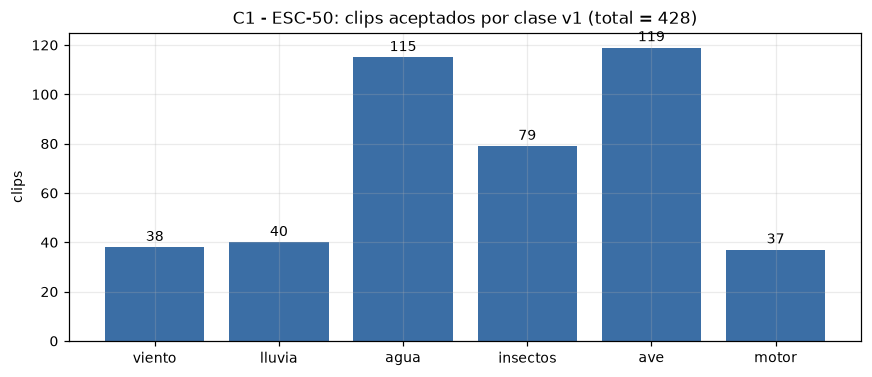

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.facecolor": "white"})

fig, ax = plt.subplots(figsize=(8, 3.5))
order = [c for c in LIVE_CLASSES if counts_c1[c] > 0]
vals = [int(counts_c1[c]) for c in order]
bars = ax.bar(order, vals, color="#3b6ea5")
ax.bar_label(bars, padding=2)
ax.set_title("C1 - ESC-50: clips aceptados por clase v1 (total = %d)" % int(counts_c1.sum()))
ax.set_ylabel("clips")
plt.tight_layout(); plt.show()

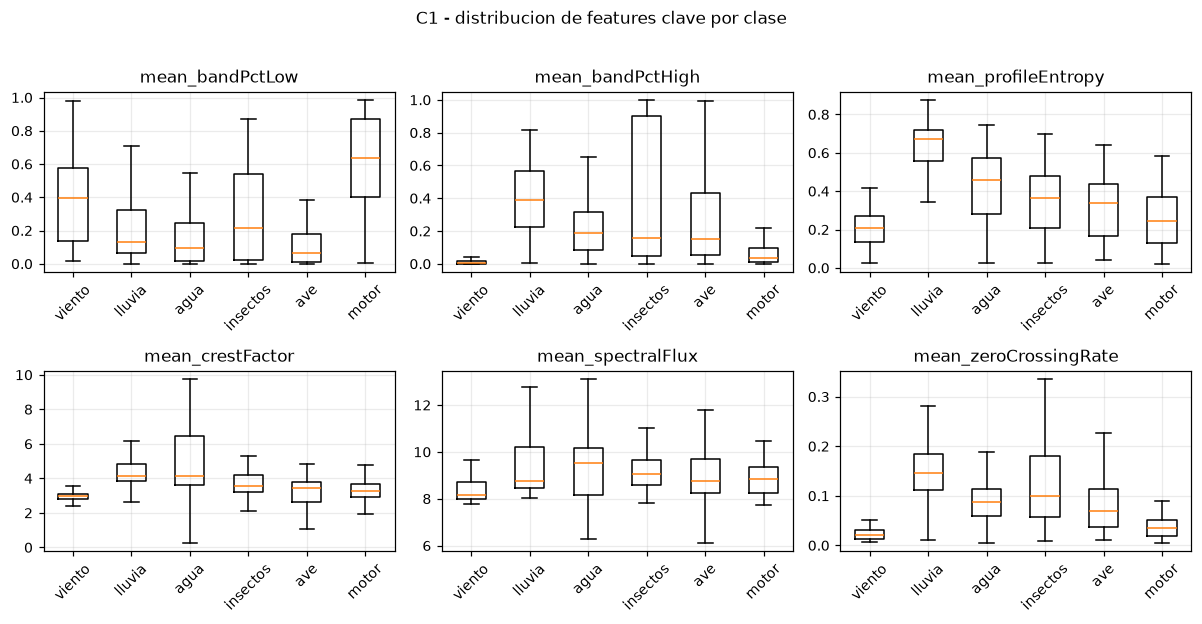

In [13]:
box_dims = ["mean_bandPctLow", "mean_bandPctHigh", "mean_profileEntropy",
            "mean_crestFactor", "mean_spectralFlux", "mean_zeroCrossingRate"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, d in zip(axes.ravel(), box_dims):
    data = [tmp.loc[tmp["class"] == c, d].to_numpy() for c in present]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(present) + 1))
    ax.set_xticklabels(present, rotation=45)
    ax.set_title(d)
fig.suptitle("C1 - distribucion de features clave por clase", y=1.02)
plt.tight_layout(); plt.show()

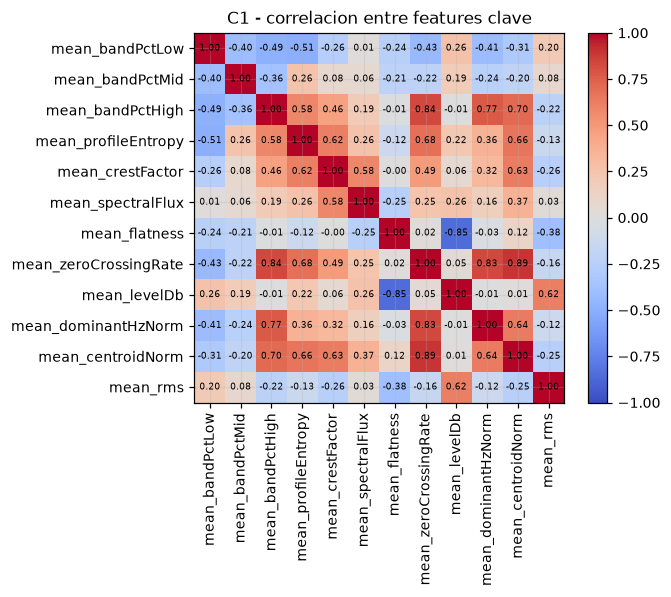

In [14]:
corr_dims = ["mean_bandPctLow", "mean_bandPctMid", "mean_bandPctHigh", "mean_profileEntropy",
             "mean_crestFactor", "mean_spectralFlux", "mean_flatness", "mean_zeroCrossingRate",
             "mean_levelDb", "mean_dominantHzNorm", "mean_centroidNorm", "mean_rms"]
C = np.corrcoef(X_c1[:, [WINDOW_SCHEMA_V2.index(d) for d in corr_dims]], rowvar=False)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_dims))); ax.set_xticklabels(corr_dims, rotation=90)
ax.set_yticks(range(len(corr_dims))); ax.set_yticklabels(corr_dims)
for i in range(len(corr_dims)):
    for j in range(len(corr_dims)):
        ax.text(j, i, f"{C[i,j]:.2f}", ha="center", va="center", fontsize=6)
ax.set_title("C1 - correlacion entre features clave")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

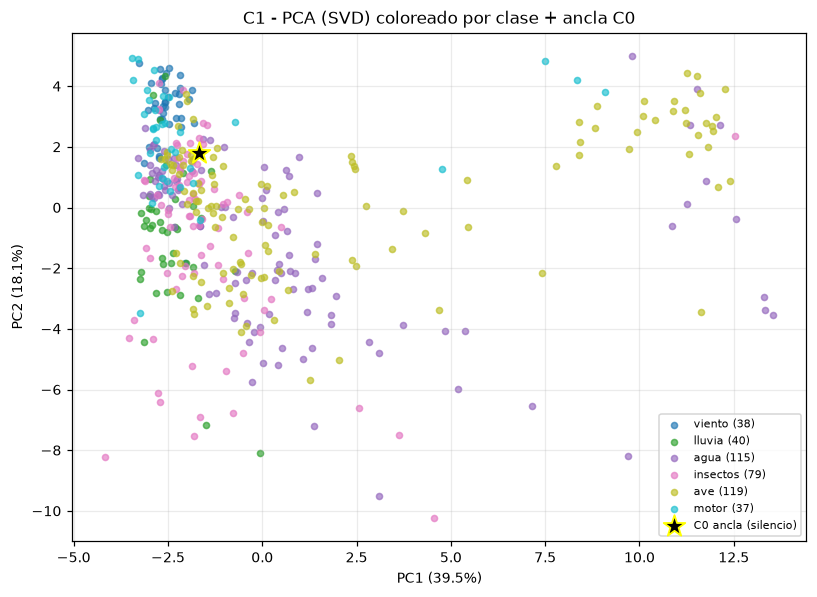

In [15]:
mu, sd = X_c1.mean(axis=0), np.where(X_c1.std(axis=0) == 0, 1.0, X_c1.std(axis=0))
Z = (X_c1 - mu) / sd
Zc = (Z - Z.mean(axis=0))
U, S, Vt = np.linalg.svd(Zc, full_matrices=False)
PC = Zc @ Vt.T
var_exp = (S ** 2) / np.sum(S ** 2)
c0_pc = ((X_c0 - mu) / sd - Z.mean(axis=0)) @ Vt.T

fig, ax = plt.subplots(figsize=(7.5, 5.5))
colors = plt.cm.tab10(np.linspace(0, 1, len(present)))
for color, c in zip(colors, present):
    m = y_c1 == c
    ax.scatter(PC[m, 0], PC[m, 1], s=16, alpha=0.65, color=color, label=f"{c} ({int(m.sum())})")
ax.scatter(c0_pc[:, 0], c0_pc[:, 1], s=220, marker="*", color="black",
           edgecolor="yellow", linewidth=1.2, label="C0 ancla (silencio)", zorder=5)
ax.set_xlabel(f"PC1 ({var_exp[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.1f}%)")
ax.set_title("C1 - PCA (SVD) coloreado por clase + ancla C0")
ax.legend(fontsize=7, loc="best")
plt.tight_layout(); plt.show()

## 8. Comparación C0 vs C1

C0 y C1 **no son el mismo dominio**. C0 es el piso de ruido rural real (1 clip, `silencio`); C1 es
material externo ESC-50 mapeado. Comparar sus distribuciones es un ejercicio de **corrimiento de dominio
(covariate shift)**, no de rendimiento.

In [16]:
mu, sd = X_c1.mean(axis=0), np.where(X_c1.std(axis=0) == 0, 1.0, X_c1.std(axis=0))
z_c0 = (X_c0[0] - mu) / sd
zt = pd.DataFrame({"C0_silencio": X_c0[0], "C1_mean": mu, "C1_std": sd, "z_vs_C1": z_c0},
                  index=WINDOW_SCHEMA_V2)
print("Top-10 dims donde el ancla C0 mas se aparta de C1 (|z|):")
zt.reindex(zt["z_vs_C1"].abs().sort_values(ascending=False).index).head(10).round(4)

Top-10 dims donde el ancla C0 mas se aparta de C1 (|z|):


,C0_silencio,C1_mean,C1_std,z_vs_C1
std_bandPctLow,0.2692,0.1026,0.0849,1.9640
mean_spectralBandwidthNorm,0.2409,0.1500,0.0541,1.6791
mean_bandPctLow,0.6216,0.2519,0.2709,1.3650
mean_bandPeakLowNorm,0.0089,0.0052,0.0028,1.3136
std_bandPeakMidNorm,0.0034,0.0127,0.0083,-1.1133
mean_spectralFlux,7.2737,9.1110,1.6610,-1.1061
mean_profileEntropy,0.1576,0.3696,0.1967,-1.0780
std_bandPctMid,0.2679,0.1452,0.1143,1.0732
std_bandPctHigh,0.0032,0.1059,0.1044,-0.9833
mean_bandPctHigh,0.0045,0.2556,0.2860,-0.8781


In [17]:
dist = {c: float(np.linalg.norm(((X_c1[y_c1 == c].mean(axis=0)) - X_c0[0]) / sd)) for c in classes_present}
dist_s = pd.Series(dist).sort_values()
print("Distancia estandarizada del ancla C0 al centroide C1 de cada clase:")
print(dist_s.round(3).to_string())
print()
print("Clase C1 mas cercana al silencio real C0:", dist_s.index[0], "(dist %.3f)" % dist_s.iloc[0])
print()
print("Lectura honesta: C1 NO contiene `silencio` ni `voz`; el ancla C0 es 1 muestra.")
print("La comparacion ilustra el corrimiento de dominio, NO mide generalizacion.")

Distancia estandarizada del ancla C0 al centroide C1 de cada clase:
motor       4.745
insectos    4.940
viento      5.032
agua        5.690
lluvia      5.855
ave         6.690

Clase C1 mas cercana al silencio real C0: motor (dist 4.745)

Lectura honesta: C1 NO contiene `silencio` ni `voz`; el ancla C0 es 1 muestra.
La comparacion ilustra el corrimiento de dominio, NO mide generalizacion.


## 9. Evaluación `rules-v0`

`rules-v0` es el baseline **determinista** (heurística por umbrales), sin aprendizaje. Esta es su
**primera evaluación sobre audio real externo** (C1). El port Python de abajo es una transcripción
**fiel** del módulo canónico `tools/cmsc-data-logger/src/rules-v0.js` — verificada 1:1 contra el original
en las 428 muestras (0 divergencias de `label`, `confidence`, `degraded` y `gate`).

> **Advertencia de honestidad.** Los umbrales se calibraron con fixtures sintéticos + un único ancla real
> (`silencio`). C1 es dominio **externo**, no rural. Por tanto estos números describen el **mecanismo** de
> `rules-v0` fuera de su calibración; **no** son una medida de rendimiento rural. `rules-v0` permanece en
> estado **`SIM`**.

In [18]:
# ===== PORT FIEL de tools/cmsc-data-logger/src/rules-v0.js =====
RULES_V0_VERSION = "acoustic-rules-v0"
RULES_V0_METHOD = "rules-v0"
RULES_V0_LABELS = ["SILENCIO", "VIENTO", "LLUVIA", "AGUA", "INSECTOS", "AVE", "VOZ", "MOTOR", "RUIDO DESCONOCIDO"]
DECISION_MARGIN_MIN = 0.1
COL = {n: i for i, n in enumerate(WINDOW_SCHEMA_V2)}
S = COL

def _clamp01(v):
    return float(min(1.0, max(0.0, v))) if np.isfinite(v) else 0.0

def _mLE(x, T, m):
    return _clamp01((T - x) / m)

def _mGE(x, T, m):
    return _clamp01((x - T) / m)

# (id, label, [(col, 'lt'|'ge', threshold, margin), ...])
RULES_V0 = [
    ("silencio", "SILENCIO", [(S['mean_bandPctHigh'], 'lt', 0.05, 0.03), (S['mean_bandPctLow'], 'lt', 0.85, 0.2),
        (S['mean_profileEntropy'], 'lt', 0.35, 0.2), (S['mean_dominantHzNorm'], 'lt', 0.1, 0.06),
        (S['std_bandPctLow'], 'ge', 0.05, 0.03), (S['mean_spectralFlux'], 'lt', 25, 15),
        (S['std_spectralFlux'], 'lt', 5, 3), (S['mean_flatness'], 'ge', 0.12, 0.08),
        (S['mean_crestFactor'], 'lt', 6, 2.5)]),
    ("motor", "MOTOR", [(S['mean_levelDb'], 'ge', 0.45, 0.3), (S['mean_bandPctLow'], 'ge', 0.85, 0.12),
        (S['mean_bandPctHigh'], 'lt', 0.05, 0.03), (S['mean_profileEntropy'], 'lt', 0.25, 0.15),
        (S['std_bandPctLow'], 'lt', 0.1, 0.07), (S['mean_centroidNorm'], 'lt', 0.3, 0.15),
        (S['mean_zeroCrossingRate'], 'lt', 0.08, 0.04), (S['mean_crestFactor'], 'lt', 3, 1.2)]),
    ("viento", "VIENTO", [(S['mean_bandPctLow'], 'ge', 0.2, 0.12), (S['mean_bandPctMid'], 'ge', 0.15, 0.1),
        (S['mean_bandPctHigh'], 'ge', 0.15, 0.1), (S['mean_profileEntropy'], 'ge', 0.45, 0.25),
        (S['mean_profileEntropy'], 'lt', 0.9, 0.1), (S['mean_flatness'], 'ge', 0.4, 0.25),
        (S['mean_crestFactor'], 'lt', 5, 2), (S['mean_spectralFlux'], 'lt', 25, 15),
        (S['std_spectralFlux'], 'lt', 5, 3)]),
    ("agua", "AGUA", [(S['mean_crestFactor'], 'ge', 4, 2), (S['mean_bandPctHigh'], 'ge', 0.5, 0.25),
        (S['mean_profileEntropy'], 'ge', 0.6, 0.25), (S['mean_spectralFlux'], 'ge', 20, 12),
        (S['std_spectralFlux'], 'ge', 10, 6)]),
    ("lluvia", "LLUVIA", [(S['mean_bandPctHigh'], 'ge', 0.6, 0.25), (S['mean_bandPctLow'], 'lt', 0.2, 0.1),
        (S['mean_profileEntropy'], 'ge', 0.8, 0.15), (S['mean_zeroCrossingRate'], 'ge', 0.3, 0.2),
        (S['mean_spectralFlux'], 'lt', 25, 15), (S['std_spectralFlux'], 'lt', 5, 3),
        (S['mean_crestFactor'], 'lt', 4, 1.5), (S['mean_flatness'], 'ge', 0.5, 0.3)]),
    ("insectos", "INSECTOS", [(S['mean_bandPctHigh'], 'ge', 0.7, 0.25), (S['mean_centroidNorm'], 'ge', 0.2, 0.12),
        (S['mean_profileEntropy'], 'lt', 0.4, 0.2), (S['std_dominantHzNorm'], 'lt', 0.1, 0.06),
        (S['std_bandPeakHighNorm'], 'lt', 0.15, 0.1), (S['std_spectralFlux'], 'lt', 10, 6),
        (S['mean_spectralFlux'], 'lt', 25, 15), (S['mean_zeroCrossingRate'], 'ge', 0.15, 0.1),
        (S['mean_flatness'], 'lt', 0.6, 0.3)]),
    ("ave", "AVE", [(S['mean_bandPctHigh'], 'ge', 0.3, 0.2), (S['mean_profileEntropy'], 'ge', 0.2, 0.12),
        (S['std_bandPctHigh'], 'ge', 0.2, 0.12), (S['std_spectralFlux'], 'ge', 20, 12),
        (S['mean_spectralFlux'], 'ge', 20, 12), (S['mean_crestFactor'], 'lt', 6, 2.5),
        (S['mean_flatness'], 'ge', 0.2, 0.12)]),
    ("voz", "VOZ", [(S['mean_bandPctMid'], 'ge', 0.5, 0.25), (S['mean_bandPctHigh'], 'lt', 0.15, 0.08),
        (S['mean_profileEntropy'], 'ge', 0.1, 0.06), (S['mean_zeroCrossingRate'], 'ge', 0.03, 0.015),
        (S['std_spectralFlux'], 'ge', 3, 2), (S['std_levelDb'], 'ge', 0.02, 0.015),
        (S['mean_flatness'], 'ge', 0.05, 0.03)]),
]

def _rule_score(conds, v):
    s = 1.0
    for idx, op, T, m in conds:
        x = v[idx]
        val = _mLE(x, T, m) if op == 'lt' else _mGE(x, T, m)
        if val < s:
            s = val
    return s

def _signal_gate(v):
    rms = v[S['mean_rms']]; le = v[S['mean_logEnergy']]; zcr = v[S['mean_zeroCrossingRate']]
    pk = v[S['mean_peakDbNorm']]; spk = v[S['std_peakDbNorm']]; crest = v[S['mean_crestFactor']]
    if rms < 0.0005 and le < 0.5 and zcr < 0.001:
        return {"label": "SILENCIO", "confidence": _clamp01((0.5 - rms) / 0.5), "degraded": True, "gate": "R0.1"}
    if spk < 0.02 and pk >= 0.99 and crest < 1.5:
        return {"label": "RUIDO DESCONOCIDO", "confidence": _clamp01((1.5 - crest) / 1.5), "degraded": True, "gate": "R0.2"}
    return None

def classify_acoustic(v):
    v = np.asarray(v, dtype=np.float64)
    if v.shape != (44,):
        raise ValueError("rules-v0: se esperaba un vector de 44 dims")
    if not np.isfinite(v).all():
        raise ValueError("rules-v0: vector con NaN/Infinity")
    g = _signal_gate(v)
    if g is not None:
        g["note"] = "puerta de senal"
        return g
    scored = sorted(((_rule_score(conds, v), lab) for _id, lab, conds in RULES_V0), key=lambda t: -t[0])
    best, blab = scored[0]
    second = scored[1][0] if len(scored) > 1 else 0.0
    if best <= 0 or (best - second) <= DECISION_MARGIN_MIN:
        return {"label": "RUIDO DESCONOCIDO", "confidence": best, "degraded": best <= 0, "gate": None,
                "note": "ninguna regla dispara o margen dudoso"}
    return {"label": blab, "confidence": best, "degraded": False, "gate": None, "note": "regla disparada"}

print("rules-v0 port listo:", RULES_V0_VERSION, "|", len(RULES_V0), "reglas vivas | margin", DECISION_MARGIN_MIN)

rules-v0 port listo: acoustic-rules-v0 | 8 reglas vivas | margin 0.1


In [19]:
preds = [classify_acoustic(v) for v in X_c1]
y_pred = np.array([p["label"] for p in preds])
conf = np.array([p["confidence"] for p in preds])
true_up = np.array([c.upper() for c in y_c1])

pred_labels = RULES_V0_LABELS
true_labels = [c.upper() for c in classes_present]
cm = pd.DataFrame(0, index=true_labels, columns=pred_labels, dtype=int)
for t, p in zip(true_up, y_pred):
    cm.loc[t, p] += 1
print("Matriz de confusion C1 (filas = verdad, columnas = prediccion rules-v0):")
cm

Matriz de confusion C1 (filas = verdad, columnas = prediccion rules-v0):


,SILENCIO,VIENTO,LLUVIA,AGUA,INSECTOS,AVE,VOZ,MOTOR,RUIDO DESCONOCIDO
VIENTO,0,0,0,0,0,0,0,1,37
LLUVIA,0,1,0,0,0,0,0,1,38
AGUA,4,0,0,0,0,0,4,0,107
INSECTOS,7,0,0,0,4,0,2,0,66
AVE,2,0,0,0,0,0,8,0,109
MOTOR,0,0,0,0,0,0,0,6,31


In [20]:
# Metricas honestas (OOD = ruido_desconocido cuenta como fallo de la clase verdadera)
results = []
for c, cu in zip(classes_present, true_labels):
    sup = int((true_up == cu).sum())
    tp = int(cm.loc[cu, cu])
    rec = tp / sup if sup else 0.0
    pred_c = int(cm[cu].sum())
    prec = tp / pred_c if pred_c else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    results.append({"clase": c, "soporte": sup, "recall": round(rec, 3), "precision": round(prec, 3), "f1": round(f1, 3)})
metrics_df = pd.DataFrame(results)
macro_f1 = float(metrics_df["f1"].mean())
covered = int((y_pred != "RUIDO DESCONOCIDO").sum())
print(metrics_df.to_string(index=False))
print()
print("macro-F1 (6 clases C1):", round(macro_f1, 3))
print("accuracy estricta:", round(float((true_up == y_pred).mean()), 3))
print("cobertura (clase viva):", round(covered / len(y_pred), 3), "-> OOD:", round(1 - covered / len(y_pred), 3))
live_conf = conf[y_pred != "RUIDO DESCONOCIDO"]
print("confidence media (predicciones vivas):", round(float(live_conf.mean()), 3) if len(live_conf) else "n/a")
print("predicciones por etiqueta:", pd.Series(y_pred).value_counts().to_dict())
print("puertas de senal activadas:", pd.Series([p.get("gate") for p in preds]).dropna().value_counts().to_dict())

   clase  soporte  recall  precision    f1
  viento       38   0.000       0.00 0.000
  lluvia       40   0.000       0.00 0.000
    agua      115   0.000       0.00 0.000
insectos       79   0.051       1.00 0.096
     ave      119   0.000       0.00 0.000
   motor       37   0.162       0.75 0.267

macro-F1 (6 clases C1): 0.06
accuracy estricta: 0.023
cobertura (clase viva): 0.093 -> OOD: 0.907
confidence media (predicciones vivas): 0.381
predicciones por etiqueta: {'RUIDO DESCONOCIDO': 388, 'VOZ': 14, 'SILENCIO': 13, 'MOTOR': 8, 'INSECTOS': 4, 'VIENTO': 1}
puertas de senal activadas: {}


In [21]:
p0 = classify_acoustic(X_c0[0])
print("C0 ancla (", c0_ids[0], "clase real", y_c0[0], ") ->")
print("  label:", p0["label"], "| confidence:", round(p0["confidence"], 4),
      "| degraded:", p0["degraded"], "| gate:", p0.get("gate"))
print()
print("Interpretacion honesta:")
print("- rules-v0 RECHAZA (OOD) la mayor parte de C1: su calibracion no cubre el dominio externo ESC-50.")
print("- El ancla C0 (silencio rural real) SI se clasifica como SILENCIO: el unico dominio calibrado.")
print("- Esto es CORRECTO segun el diseno: una heuristica que duda es honesta; adivinar seria ruido.")

C0 ancla ( ac_20261006_215109_000 clase real silencio ) ->
  label: SILENCIO | confidence: 0.9621 | degraded: False | gate: None

Interpretacion honesta:
- rules-v0 RECHAZA (OOD) la mayor parte de C1: su calibracion no cubre el dominio externo ESC-50.
- El ancla C0 (silencio rural real) SI se clasifica como SILENCIO: el unico dominio calibrado.
- Esto es CORRECTO segun el diseno: una heuristica que duda es honesta; adivinar seria ruido.


### 9.1 Veredicto de la evaluación `rules-v0`

`rules-v0` **no generaliza** al dominio externo C1: la gran mayoría de clips ESC-50 caen en
`RUIDO DESCONOCIDO` (bucket OOD), y solo una fracción recibe clase viva. Esto **no es un fallo**: es el
comportamiento esperado de un clasificador cuyos umbrales se calibraron sobre síntesis + un solo ancla real.

**Hallazgos (explícitos, sin ocultar ni suavizar):**

- `n(C0) = 1` (un único clip real) · `C1 = 428` clips.
- Corrimiento de dominio (*covariate shift*) marcado entre C0 (`REAL-LOCAL`) y C1 (`REF`).
- `rules-v0` sobre C1: **macro-F1 ≈ 0.06** · cobertura de clase viva **9.3 %** → **90.7 % OOD**.
- El ancla C0 (silencio rural real) **sí** se clasifica como `SILENCIO` (confidence ≈ 0.96).
- Conclusión: `rules-v0` es un **baseline heurístico honesto, no un modelo ML de producción**.

Conclusión operativa: `rules-v0` sirve como **baseline determinista y auditable del dominio propio**,
no como clasificador del corpus externo. Su promoción a `ml-v1` (aprendido y calibrado) sigue **bloqueada**
hasta cerrar los gates del dataset propio (ver sección 10).

## 10. Roadmap ML

Nada se entrena aquí. Esta sección declara lo que **falta** y el orden de gates para que un modelo
aprendido (`ml-v1-tabular`) pueda existir sin romper la honestidad del ecosistema. C1 es **referencia**
(`REF`): alimenta pre-entrenamiento / bootstrap, **jamás** evaluación de S81. La evaluación de S81 solo
puede ocurrir sobre **C0** (audio rural propio).

> **Observación futura.** C1 no cuenta para el cumplimiento de G-DS-2. Las 150 muestras por clase
> siguen siendo un requisito de C0 `REAL-LOCAL`.

In [22]:
roadmap = pd.DataFrame({
    "clase": LIVE_CLASSES,
    "en_C1_REF": [int(counts_c1[c]) for c in LIVE_CLASSES],
    "objetivo_G_DS_2": [150] * len(LIVE_CLASSES),
})
roadmap["faltante_propio"] = (roadmap["objetivo_G_DS_2"] - roadmap["en_C1_REF"]).clip(lower=0)
print("Plan de datos (C0 propio). C1 NO cuenta para la cuota propia; se lista solo como referencia.")
roadmap

Plan de datos (C0 propio). C1 NO cuenta para la cuota propia; se lista solo como referencia.


,clase,en_C1_REF,objetivo_G_DS_2,faltante_propio
0,silencio,0,150,150
1,viento,38,150,112
2,lluvia,40,150,110
3,agua,115,150,35
4,insectos,79,150,71
5,ave,119,150,31
6,voz,0,150,150
7,motor,37,150,113


### Gates y secuencia (no ejecutados)

| Gate | Criterio | Estado actual |
|---|---|---|
| **G-DS-1** | taxonomía + mids verificados en `schema` | `FAIL` (7 mids `UNVERIFIED`) |
| **G-DS-2** | ≥150 clips propios / clase viva | abierto (C0 = 1 clip) |
| **G-DS-6** | acuerdo entre anotadores (κ real) | `PENDING` (requiere doble anotación) |
| **G-M-1** | `rules-v0` reproducido y documentado | **cerrado por este notebook** (SIM) |
| **G-M-2** | `ml-v1-tabular` supera a `rules-v0` (macro-F1 y ECE) sobre **C0** | bloqueado por G-DS-2 |
| **G-M-3** | ECE ≤ 0,10 (confianza calibrada) | bloqueado (no hay modelo) |

**Secuencia propuesta (cada paso = misión explícita):**

1. Captura C0 → cerrar G-DS-2 (≥150/clase viva) y G-DS-1/G-DS-6.
2. Split reproducible por `(session_id, place_id)` → `SPLITEADO`.
3. `ml-v1-tabular` (HistGB / LogReg → ONNX ≤ 15 MB) entrenado **solo con C0**.
4. C1 (`REF`) como apoyo de pre-entrenamiento/bootstrap, **nunca** en `train/validation/test` de C0.
5. Calibración (ECE) + `validation_metrics.json` + `model_card.md` → gate G-M-2/G-M-3.
6. S81 pasa a `REAL-LOCAL` **solo** con modelo validado sobre datos propios.

**Nunca:** entrenar con C1 y evaluar como si fuera rural · presentar `rules-v0` como IA · declarar
métricas sin artefacto de gobernanza.

## Cierre · invariantes respetados

- Sin entrenar modelos · sin S81 · sin S82 · sin modificar datasets · notebook únicamente.
- Lectura pura de C0 (1 clip) y C1 (428 clips); port `rules-v0` verificado 1:1 contra el módulo JS.
- Estado honesto: C0 `CAPTADO_INICIAL` · C1 `INVENTARIADO` (no `CONSUMIBLE`) · `rules-v0` `SIM` · S81/S82 `DISENO`.
- La documentación canónica sigue siendo la fuente de verdad; este notebook es su implementación reproducible.